#🍔Trabajo Práctico Integrador: Pipeline ETL & Inteligencia de Mercado (Food Delivery)
## Contexto de Negocio

Usted ha sido contratado como Data Engineer y Analista BI por el CEO de una nueva startup 
de Food Delivery que busca expandirse en Estados Unidos. Antes de lanzar la aplicación y 
decidir en qué ciudades invertir, el directorio necesita entender cómo operan sus competidores 
actuales, qué categorías dominan el mercado y cómo se comportan los precios según la región. 
El equipo de Web Scraping le ha entregado dos archivos crudos. Su misión es construir un 
pipeline ETL completo: extraer los datos, realizar una limpieza profunda (separar direcciones, 
traducir rangos de precios), optimizar el tamaño, cargarlos en un motor SQL local (SQLite) y, 
finalmente, responder a las preguntas críticas del CEO utilizando consultas SQL y gráficos 
profesionales.

In [0]:
#Instalamos librerías para visualización y conexión a SQL
#Nota: en Databricks, %pip reinicia Python, por eso los imports van en la celda siguiente
%pip install seaborn sqlalchemy

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


# 📥FASE 1: EXTRACT
Lectura de los archivos CSV desde el Volume de Databricks.

In [0]:
#Librerías necesarias para todo el proyecto
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text

In [0]:
#Verificamos qué archivos hay en el Volume
display(dbutils.fs.ls("/Volumes/workspace/default/delivery_raw/"))

path,name,size,modificationTime
dbfs:/Volumes/workspace/default/delivery_raw/restaurant_menus_parte_1.csv,restaurant_menus_parte_1.csv,13282742,1791683630000
dbfs:/Volumes/workspace/default/delivery_raw/restaurant_menus_parte_10.csv,restaurant_menus_parte_10.csv,11965071,1791683635000
dbfs:/Volumes/workspace/default/delivery_raw/restaurant_menus_parte_2.csv,restaurant_menus_parte_2.csv,12474888,1791683630000
dbfs:/Volumes/workspace/default/delivery_raw/restaurant_menus_parte_3.csv,restaurant_menus_parte_3.csv,14771057,1791683631000
dbfs:/Volumes/workspace/default/delivery_raw/restaurant_menus_parte_4.csv,restaurant_menus_parte_4.csv,17089780,1791683633000
dbfs:/Volumes/workspace/default/delivery_raw/restaurant_menus_parte_5.csv,restaurant_menus_parte_5.csv,19318585,1791683633000
dbfs:/Volumes/workspace/default/delivery_raw/restaurant_menus_parte_6 (1).csv,restaurant_menus_parte_6 (1).csv,18331037,1791683633000
dbfs:/Volumes/workspace/default/delivery_raw/restaurant_menus_parte_6.csv,restaurant_menus_parte_6.csv,18331037,1791683634000
dbfs:/Volumes/workspace/default/delivery_raw/restaurant_menus_parte_7.csv,restaurant_menus_parte_7.csv,17090738,1791683634000
dbfs:/Volumes/workspace/default/delivery_raw/restaurant_menus_parte_8.csv,restaurant_menus_parte_8.csv,18425671,1791683633000


📝El dataset de menús se recibió particionado en 10 archivos. Además, existe el archivo restaurant_menus_parte_6 (1).csv, que tiene exactamente el mismo tamaño que parte_6.csv: es una copia duplicada y se excluye de la carga.

In [0]:
#Ruta donde están los archivos CSV
ruta = "/Volumes/workspace/default/delivery_raw/"

#Cargamos el catálogo de restaurantes
df_restaurantes = pd.read_csv(ruta + "restaurants.csv")

#Cargamos las 10 partes de menús sin el duplicado y las unimos en un solo DataFrame
partes = [pd.read_csv(f"{ruta}restaurant_menus_parte_{i}.csv") for i in range(1, 11)]
df_menus = pd.concat(partes, ignore_index=True)

In [0]:
#Validamos que todas las partes tengan la misma estructura de columnas
for i, p in enumerate(partes, 1):
    print(i, list(p.columns))

#Contamos filas duplicadas tras la unión que se eliminan en la fase TRANSFORM
print("Duplicados:", df_menus.duplicated().sum())

#Liberamos memoria: ya no necesitamos las partes sueltas
del partes

1 ['restaurant_id', 'category', 'name', 'description', 'price']
2 ['restaurant_id', 'category', 'name', 'description', 'price']
3 ['restaurant_id', 'category', 'name', 'description', 'price']
4 ['restaurant_id', 'category', 'name', 'description', 'price']
5 ['restaurant_id', 'category', 'name', 'description', 'price']
6 ['restaurant_id', 'category', 'name', 'description', 'price']
7 ['restaurant_id', 'category', 'name', 'description', 'price']
8 ['restaurant_id', 'category', 'name', 'description', 'price']
9 ['restaurant_id', 'category', 'name', 'description', 'price']
10 ['restaurant_id', 'category', 'name', 'description', 'price']
Duplicados: 2543


## 🔍Data Profiling
Diagnóstico inicial: dimensiones, tipos de datos y valores nulos de ambos DataFrames.

In [0]:
#Diagnóstico inicial de ambos DataFrames: dimensiones, tipos y nulos
for nombre, df in [("Restaurantes", df_restaurantes), ("Menús", df_menus)]:
    print(f"===== {nombre} =====")
    print("Dimensiones:", df.shape)
    print("\nTipos de datos:\n", df.dtypes)
    print("\nNulos por columna:\n", df.isnull().sum())
    print()

===== Restaurantes =====
Dimensiones: (63469, 11)

Tipos de datos:
 id                int64
position          int64
name             object
score           float64
ratings         float64
category         object
price_range      object
full_address     object
zip_code         object
lat             float64
lng             float64
dtype: object

Nulos por columna:
 id                  0
position            0
name                0
score           28167
ratings         28167
category           85
price_range     10617
full_address      453
zip_code          517
lat                 0
lng                 0
dtype: int64

===== Menús =====
Dimensiones: (836350, 5)

Tipos de datos:
 restaurant_id     int64
category         object
name             object
description      object
price            object
dtype: object

Nulos por columna:
 restaurant_id         0
category              0
name                  1
description      200324
price                 0
dtype: int64



##Hallazgos del diagnóstico:
- score y ratings tienen la misma cantidad de nulos: son restaurantes sin calificaciones.
- price en menús está como texto (object), por lo que debe convertirse a número.
- price_range tiene nulos que quedarán sin categoría de precio.
- El dataset de menús recibido tiene 836 mil filas y la guía menciona 5 millones, entonces se trabaja con la versión entregada.

# 🧹FASE 2: TRANSFORM
Limpieza, ingeniería de características y reducción del dataset.

### 🏷️Paso 1: Mapeo de rangos de precio

In [0]:
#Diccionario que traduce los símbolos de precio a texto entendible
mapa_precios = {
    "$": "Económico",
    "$$": "Moderadamente caro",
    "$$$": "Caro",
    "$$$$": "Muy caro"
}

#Quitamos espacios ocultos y aplicamos la traducción
df_restaurantes["rango_de_precios"] = df_restaurantes["price_range"].str.strip().map(mapa_precios)

#Verificamos el resultado incluyendo nulos
print(df_restaurantes["rango_de_precios"].value_counts(dropna=False))

rango_de_precios
Económico             37637
Moderadamente caro    14952
NaN                   10618
Caro                    237
Muy caro                 25
Name: count, dtype: int64


In [0]:
#Revisamos valores de price_range que no se pudieron traducir
print(df_restaurantes.loc[
    df_restaurantes["price_range"].notna() & df_restaurantes["rango_de_precios"].isna(),
    "price_range"
].unique())

['$$$$$$$$$$$$$$$$$']


📝 Se detectó 1 registro con price_range error de scraping. Al no corresponder a ninguna categoría válida, se mantiene como nulo.

### 📍Paso 2: Desanidado de la dirección (Split)

In [0]:
#Separamos la dirección en 3 columnas usando la coma como separador
#n=2 corta solo en las 2 primeras comas, así siempre salen exactamente 3 columnas
df_restaurantes[["calle", "ciudad", "estado_zip"]] = (
    df_restaurantes["full_address"].str.split(",", n=2, expand=True)
)

#Quitamos espacios ocultos en las nuevas columnas
df_restaurantes["ciudad"] = df_restaurantes["ciudad"].str.strip()
df_restaurantes["estado_zip"] = df_restaurantes["estado_zip"].str.strip()

#Verificamos el resultado
df_restaurantes[["full_address", "calle", "ciudad", "estado_zip"]].head()

,full_address,calle,ciudad,estado_zip
0,"224 Daniel Payne Drive, Birmingham, AL, 35207",224 Daniel Payne Drive,Birmingham,"AL, 35207"
1,"1521 Pinson Valley Parkway, Birmingham, AL, 35217",1521 Pinson Valley Parkway,Birmingham,"AL, 35217"
2,"541-B Graymont Ave, Birmingham, AL, 35204",541-B Graymont Ave,Birmingham,"AL, 35204"
3,"1580 Montgomery Highway, Hoover, AL, 35226",1580 Montgomery Highway,Hoover,"AL, 35226"
4,"314 17th St N, Birmingham, AL, 35203",314 17th St N,Birmingham,"AL, 35203"


### ⭐Paso 3: Filtro de calidad

In [0]:
#Eliminamos restaurantes sin puntaje o con puntaje 0
#.copy() crea una copia de los datos para poder modificarlos sin alterar la tabla original.
df_restaurantes = df_restaurantes[
    df_restaurantes["score"].notna() & (df_restaurantes["score"] != 0)
].copy()

# Estandarizamos la categoría a minúsculas
df_restaurantes["category"] = df_restaurantes["category"].str.lower().str.strip()

print("Restaurantes tras filtro de calidad:", df_restaurantes.shape)

Restaurantes tras filtro de calidad: (35302, 15)


### 💲Paso 4: Limpieza de menús

In [0]:
#Eliminamos filas duplicadas de menús generadas en el scraping
filas_antes = len(df_menus)
df_menus = df_menus.drop_duplicates()
print("Duplicados eliminados:", filas_antes - len(df_menus))

Duplicados eliminados: 2543


In [0]:
#Convertimos el precio de texto a número decimal
df_menus["price"] = (
    df_menus["price"]
    .astype(str)
    .str.replace(" USD", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.strip()
)
df_menus["price"] = pd.to_numeric(df_menus["price"], errors="coerce")

#Eliminamos ítems con precio nulo, cero o negativo que son datos inválidos
df_menus = df_menus[df_menus["price"].notna() & (df_menus["price"] > 0)].copy()

print("Menús tras limpieza:", df_menus.shape)
print(df_menus["price"].describe())

/home/spark-d63d9621-5a1a-48d4-9e67-23/.ipykernel/65/command-4626758296724770-100519379:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_menus["price"] = (


Menús tras limpieza: (796260, 5)
count    796260.000000
mean         10.352839
std          11.561700
min           0.010000
25%           4.390000
50%           8.380000
75%          13.190000
max        1099.990000
Name: price, dtype: float64


/home/spark-d63d9621-5a1a-48d4-9e67-23/.ipykernel/65/command-4626758296724770-100519379:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_menus["price"] = pd.to_numeric(df_menus["price"], errors="coerce")


> 📝 Además de los precios en 0 que pide la guía, se encontraron **precios negativos** (error de datos), que también se eliminan. El precio máximo (~1,100 USD) corresponde probablemente a pedidos de catering; se conserva, pero puede elevar los promedios.

## ⚡Optimización y cruce de datos

In [0]:
#Paso 5: Nos quedamos solo con restaurantes consolidados
df_restaurantes = df_restaurantes[df_restaurantes["ratings"] > 100].copy()
print("Restaurantes consolidados:", df_restaurantes.shape)

Restaurantes consolidados: (8702, 15)


In [0]:
#Paso 6: INNER JOIN entre restaurantes consolidados y sus menús
df_master = pd.merge(
    df_restaurantes,
    df_menus,
    left_on="id",
    right_on="restaurant_id",
    how="inner",
    suffixes=("_restaurante", "_plato")   #ayuda a distinguir name/category del restaurante y del plato
)

print("df_master:", df_master.shape)
print("Restaurantes con menú en df_master:", df_master["id"].nunique())
df_master.head()

df_master: (63186, 20)
Restaurantes con menú en df_master: 671


,id,position,name_restaurante,score,ratings,category_restaurante,price_range,full_address,zip_code,lat,lng,rango_de_precios,calle,ciudad,estado_zip,restaurant_id,category_plato,name_plato,description,price
0,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",$,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,Económico,4756 S 27th St,Milwaukee,"WI, 53221",1739,Picked for you,Spring Roll,"Three rolls. Shrimps, sliced pork, vermicelli ...",6.99
1,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",$,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,Económico,4756 S 27th St,Milwaukee,"WI, 53221",1739,Picked for you,Egg Roll,"Pork, carrot, bean thread noodles, and are wra...",6.50
2,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",$,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,Económico,4756 S 27th St,Milwaukee,"WI, 53221",1739,Picked for you,Grilled Pork,Foot long.,9.50
3,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",$,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,Económico,4756 S 27th St,Milwaukee,"WI, 53221",1739,Picked for you,House Special,"Rice noodle with steak, rare, flank, brisket, ...",10.95
4,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",$,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,Económico,4756 S 27th St,Milwaukee,"WI, 53221",1739,Picked for you,Rice Noodle with Rare Steak,NaN,10.95


In [0]:
#Paso 7: Liberamos memoria eliminando el DataFrame de menús, ya integrado en df_master
del df_menus

# 💾FASE 3: LOAD
Carga de la tabla final en una base de datos SQLite local

In [0]:
#Ruta de la base de datos SQLite
#Se usa /tmp porque es un disco local que permite escribir archivos SQLite
ruta_db = "/tmp/delivery_insights.db"

#Creamos el motor de conexión a SQLite
engine = create_engine(f"sqlite:///{ruta_db}")

#Cargamos df_master como tabla en la base de datos
df_master.to_sql(
    "master_food_data",
    con=engine,
    if_exists="replace",
    index=False
)
print("Tabla master_food_data cargada correctamente")

Tabla master_food_data cargada correctamente


In [0]:
#Verificamos que la tabla se cargó con la misma cantidad de filas que df_master
with engine.connect() as conn:
    filas_db = pd.read_sql(text("SELECT COUNT(*) AS filas FROM master_food_data"), conn)
print("Filas en df_master:", len(df_master))
print("Filas en SQLite:   ", filas_db["filas"][0])

Filas en df_master: 63186
Filas en SQLite:    63186


# 📊 FASE 4: BUSINESS INTELLIGENCE
Reporte al CEO: consultas SQL sobre master_food_data y visualización de resultados.

In [0]:
#Función para ejecutar SQL y devolver un DataFrame
def consultar(query):
    with engine.connect() as conn:
        return pd.read_sql(text(query), conn)

#Estilo general de los gráficos
sns.set_theme(style="whitegrid")

## 🗺️Pregunta 1: ¿Cuáles son las 5 ciudades con más restaurantes consolidados?

In [0]:
#Consulta en SQL
query_1 = """
SELECT ciudad,
        COUNT(DISTINCT id) AS cantidad_restaurantes
FROM master_food_data
WHERE ciudad IS NOT NULL
GROUP BY ciudad
ORDER BY cantidad_restaurantes DESC
LIMIT 5
"""
df_q1 = consultar(query_1)
df_q1

,ciudad,cantidad_restaurantes
0,Milwaukee,122
1,Seattle,119
2,Lynnwood,40
3,Everett,32
4,Bellevue,28


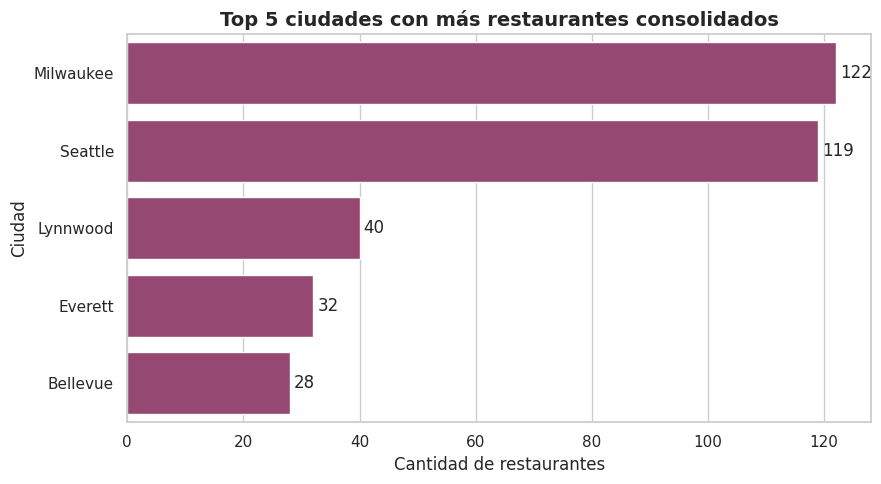

In [0]:
#Gráfico de barras horizontal ordenado de mayor a menor
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=df_q1, x="cantidad_restaurantes", y="ciudad", color="#A23B72", ax=ax)
ax.bar_label(ax.containers[0], padding=3)
ax.set_title("Top 5 ciudades con más restaurantes consolidados", fontsize=14, fontweight="bold")
ax.set_xlabel("Cantidad de restaurantes")
ax.set_ylabel("Ciudad")
plt.tight_layout()
plt.show()

## 💰Pregunta 2: ¿Cómo se distribuyen los restaurantes por rango de precios?

In [0]:
#SQL
query_2 = """
SELECT rango_de_precios,
       COUNT(DISTINCT id) AS cantidad_restaurantes
FROM master_food_data
WHERE rango_de_precios IS NOT NULL
GROUP BY rango_de_precios
ORDER BY CASE rango_de_precios
            WHEN 'Económico' THEN 1
            WHEN 'Moderadamente caro' THEN 2
            WHEN 'Caro' THEN 3
            WHEN 'Muy caro' THEN 4
         END
"""
df_q2 = consultar(query_2)
df_q2

,rango_de_precios,cantidad_restaurantes
0,Económico,450
1,Moderadamente caro,157
2,Caro,4


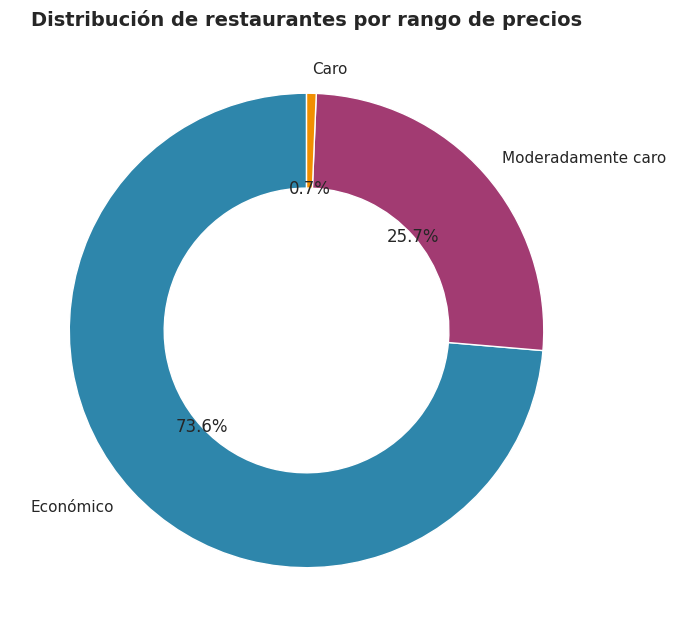

In [0]:
#Gráfico de dona con porcentajes
fig, ax = plt.subplots(figsize=(7, 7))
colores = ["#2E86AB", "#A23B72", "#F18F01", "#C73E1D"]
ax.pie(
    df_q2["cantidad_restaurantes"],
    labels=df_q2["rango_de_precios"],
    autopct="%1.1f%%",
    startangle=90,
    colors=colores[:len(df_q2)],
    wedgeprops={"width": 0.4}
)
ax.set_title("Distribución de restaurantes por rango de precios", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 🍽️Pregunta 3: ¿En cuál de las 3 ciudades más populares es más caro comer?

In [0]:
#SQL
query_3 = """
WITH top_ciudades AS (
    SELECT ciudad
    FROM master_food_data
    WHERE ciudad IS NOT NULL
    GROUP BY ciudad
    ORDER BY COUNT(DISTINCT id) DESC
    LIMIT 3
)
SELECT m.ciudad,
       ROUND(AVG(m.price), 2) AS precio_promedio_plato,
       COUNT(*) AS cantidad_platos
FROM master_food_data AS m
INNER JOIN top_ciudades AS t
    ON m.ciudad = t.ciudad
GROUP BY m.ciudad
ORDER BY precio_promedio_plato DESC
"""
df_q3 = consultar(query_3)
df_q3

,ciudad,precio_promedio_plato,cantidad_platos
0,Seattle,11.97,9657
1,Lynnwood,10.82,3609
2,Milwaukee,9.53,11667


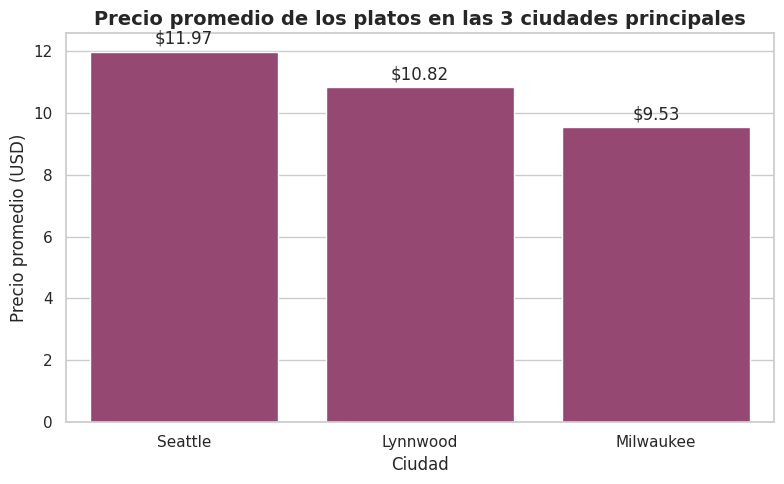

In [0]:
#Gráfico de barras
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=df_q3, x="ciudad", y="precio_promedio_plato", color="#A23B72", ax=ax)
ax.bar_label(ax.containers[0], fmt="$%.2f", padding=3)
ax.set_title("Precio promedio de los platos en las 3 ciudades principales", fontsize=14, fontweight="bold")
ax.set_xlabel("Ciudad")
ax.set_ylabel("Precio promedio (USD)")
plt.tight_layout()
plt.show()

## ⭐Pregunta 4: ¿Un restaurante más caro garantiza una mejor experiencia?

In [0]:
#SQL
query_4 = """
WITH restaurantes AS (
    SELECT DISTINCT id, rango_de_precios, score
    FROM master_food_data
    WHERE rango_de_precios IS NOT NULL
)
SELECT rango_de_precios,
       ROUND(AVG(score), 2) AS score_promedio,
       COUNT(*) AS cantidad_restaurantes
FROM restaurantes
GROUP BY rango_de_precios
ORDER BY CASE rango_de_precios
            WHEN 'Económico' THEN 1
            WHEN 'Moderadamente caro' THEN 2
            WHEN 'Caro' THEN 3
            WHEN 'Muy caro' THEN 4
         END
"""
df_q4 = consultar(query_4)
df_q4

,rango_de_precios,score_promedio,cantidad_restaurantes
0,Económico,4.62,450
1,Moderadamente caro,4.64,157
2,Caro,4.45,4


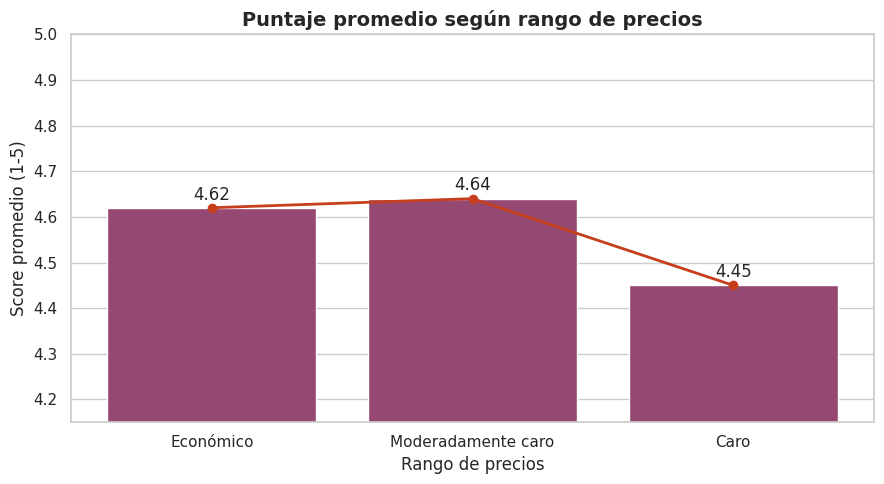

In [0]:
#Gráfico de barras con línea de tendencia
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=df_q4, x="rango_de_precios", y="score_promedio", color="#A23B72", ax=ax)
ax.plot(range(len(df_q4)), df_q4["score_promedio"], color="#C73E1D", marker="o", linewidth=2)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
ax.set_ylim(df_q4["score_promedio"].min() - 0.3, 5)
ax.set_title("Puntaje promedio según rango de precios", fontsize=14, fontweight="bold")
ax.set_xlabel("Rango de precios")
ax.set_ylabel("Score promedio (1-5)")
plt.tight_layout()
plt.show()

### # 💡Conclusiones:
- Milwaukee (122) y Seattle (119) acumulan tres veces más restaurantes consolidados que el resto del top 5, siendo los mercados más maduros, pero también los más competidos.
- La hipótesis del CEO no se cumple porque el 73.6% de los restaurantes consolidados es Económico y solo el 0.7% Caro, además, ningún “Muy caro” pasó los filtros, por lo que el mercado compite principalmente por precio bajo.
- Seattle es la ciudad más cara para comer ($11.97 por plato), unos $2.44 más que Milwaukee ($9.53), lo que sugiere un mayor margen potencial en Seattle y una mayor sensibilidad al precio en Milwaukee.
- Un precio más alto no asegura una mejor experiencia: Económico (4,62) y Moderadamente caro (4,64) tienen calificaciones prácticamente iguales, y la categoría Caro (4,45) se basa en tan sólo 4 restaurantes, por lo que no es concluyente.